# Learning the COM's γ with a neural network (end-to-end through the COM)

**The question.** The NMPC uses a simplified physics model, the **COM**, with 11 tuning multipliers
**γ = (p1 … p11)**. Today γ comes from an interpolation table tuned at −5 and −10 °C (`prepParaVec`).
Here a small neural network predicts γ from the operating point instead, trained so that the COM's predictions
match the detailed Simulink model (the **HFM**).

```
operating point ──► γ network ──► γ (11 values) ──► COM, predicts ahead ──► compare with HFM
                         ▲                                                       │
                         └───────────── gradient back through the COM ───────────┘
```

| term | meaning |
|---|---|
| **HFM** | high-fidelity model: the Simscape model in Simulink. Treated as the truth. |
| **COM** | control-oriented model, `Source Files/dynamics_mexfreeNew.m` (PyTorch copy: `com_torch.py`) |
| **γ** | multipliers that scale terms in the COM. γ = 1 is "nominal". |
| **30-s test** | start from the true state, predict 30 s ahead (as the NMPC does every second) |
| **free run** | start once at t = 0 and predict the whole hour without resets (paper Fig. 2 / Table 1) |

## How to run
1. Once: `conda env create -f environment.yml` (or `pip install torch numpy scipy matplotlib CoolProp`).
2. Open this notebook from the `python/` folder and **Run All**.
   - `TRAIN = False` (default): loads the trained network `models/history/gamma11_wltchw_only_17nov.pt`. About **2–4 min** on a laptop,
     mostly the free run (CoolProp every second).
   - `TRAIN = True`: runs the 3-step training again (`partB.train_recipe`, about **80 min** on a laptop CPU).
   - Section 6 (several drive cycles) loads `results/cycles_experiment_results.pt` from `train_gamma11_step1_base.py` (seconds).
     Set `RUN_EXPERIMENT = True` there to train and test again (capped at 2 h).
3. Data: `Data/tuning_data_<T>.mat` (old exports, −5/−7/−10 °C) and `Results/run_*/training_data_rule_T<T>.mat`
   (new exports, 0 … −30 °C). Each profile is prepared once (~15 s) and cached in `_cache/`.

**Files:** `gamma_net.py` (data, network, training, tests) · `train_gamma11_step1_base.py` + `report_cycles_experiment.py` (section 6) · `com_torch.py` (the COM, checked against MATLAB to
~1e-12 with `test_com_port.py`) · `est_coolprop.py` (`estimateParameters.m` in Python).

## 0. Settings

In [1]:
TRAIN      = False                 # True: train again with the 3-step recipe (~80 min)
FREE_RUN_T = (10, 7, 5)            # temperatures for the full-hour free run (the paper's three); all 9 take ~5 min
N_THREADS  = 4                     # CPU threads for PyTorch

TRAIN_T = (0, 5, 10, 15, 20, 30)   # ambient temperatures used for training (5 means -5 °C)
TEST_T  = (7, 12, 25)              # never used for training

import time
from pathlib import Path
import numpy as np
import torch
import matplotlib.pyplot as plt
from gamma_net import *

torch.set_num_threads(N_THREADS)
DATA, RESULTS, CACHE = REPO / "Data", REPO / "Results", DATA_CACHE   # Results/ is optional (not in git)
MODEL_FILE = MODELS / "history" / "gamma11_wltchw_only_17nov.pt"   # first network, WLTCHW only (17 Nov)
assert DATA.exists(), "Open the notebook from the python/ folder."
print("torch", torch.__version__, "| threads", torch.get_num_threads())

torch 2.14.1+cpu | threads 4


## 1. Data
All 9 profiles are the same 1-hour drive cycle with the rule-based controller, at 1 Hz: HFM states in COM units
(K, Pa, SOC), the 6 inputs, the CoolProp properties and the supervisor commands (port of
`thermalLogicAndEstimation.m`; superheat fixed at 2 K as in the NMPC).

Known differences between old and new data (not errors): the new runs use 1200-rpm pumps (old: 900 rpm), and
in the current new exports `cabIntT` is a plain average of glass/doors/roof (the updated
`export_training_data.m` exports the COM's m·cp-weighted value; re-running the simulations fixes it).

In [2]:
t0 = time.time()
PB = load_all_profiles(DATA, RESULTS, CACHE)       # keys = |Tamb|: PB[12] is -12 °C
missing = [T for T in TRAIN_T + TEST_T if T not in PB]
assert not missing, f"no data for Tamb = {[-T for T in missing]} °C: check the Results/run_* folders"
print(f"loaded in {time.time() - t0:.0f} s")

  Tamb  -10 °C  old  Data/tuning_data_10.mat  (cache)
  Tamb   -5 °C  old  Data/tuning_data_5.mat  (cache)
  Tamb   -7 °C  old  Data/tuning_data_7.mat  (cache)
  Tamb  -20 °C  new  Results/run_2026_11_14_19_30_25/training_data_rule_T20.mat  (cache)
  Tamb   +0 °C  new  Results/run_2026_11_15_13_45_52/training_data_rule_T0.mat  (cache)
  Tamb  -12 °C  new  Results/run_2026_11_15_13_52_12/training_data_rule_T12.mat  (cache)
  Tamb  -15 °C  new  Results/run_2026_11_15_14_00_40/training_data_rule_T15.mat  (cache)
  Tamb  -25 °C  new  Results/run_2026_11_15_14_05_16/training_data_rule_T25.mat  (cache)
  Tamb  -30 °C  new  Results/run_2026_11_15_14_10_40/training_data_rule_T30.mat  (cache)
loaded in 0 s


## 2. The γ network
**Inputs (25)** at the window start: ambient temperature, the 9 states, the 6 inputs now and their 30-s average,
motor/inverter heat and battery current. **Network:** 25 → 64 → 64 → 11 (tanh). **Output:** the 11 γ, each
limited to 0.1 … 10. γ is computed once at the window start and held, like `prepParaVec` in the NMPC.

**Training** (`train_recipe` in `gamma_net.py`) — every window starts from the HFM state, the COM predicts ahead,
and the error is back-propagated through the COM:
1. 300 s windows from scratch, "balanced" loss (each state divided by the γ = 1 error);
2. fine-tune on 300 s + 1200 s windows with **p_out weighted at 3 bar** (its balanced scale was ~25 bar, which
   made the pressure almost weightless) — this fixes the slow p_out drift in long runs;
3. fine-tune on 300 s windows **including the compressor start-up**. Windows are only dropped where the HFM
   p_out exceeds R134a's critical pressure (0 °C start-up), because CoolProp has no properties there.

**Compared against:** γ = 1 (nominal COM) and the interpolation table (what the NMPC uses today).

In [3]:
table = TableGamma(DATA / "tunedVariables_minus5_minus10.mat")
gamma_net = GammaNet()
if TRAIN:
    gamma_net, MU, SD, hist = train_recipe(PB, TRAIN_T)
    torch.save(dict(state=gamma_net.state_dict(), mu=MU, sd=SD, train_T=TRAIN_T, hist=hist), MODEL_FILE)
    plt.figure(figsize=(6, 3)); plt.semilogy(hist); plt.xlabel("iteration"); plt.ylabel("training loss")
    plt.grid(alpha=.3); plt.show()
else:
    saved = torch.load(MODEL_FILE, weights_only=False)
    assert tuple(saved["train_T"]) == tuple(TRAIN_T), "saved model used other training temperatures: set TRAIN = True"
    MU, SD = saved["mu"], saved["sd"]
    gamma_net.load_state_dict(saved["state"])
    print(f"loaded {MODEL_FILE}")
gamma_net.eval()
norm = lambda z: (z - MU) / SD

loaded gammanet_partB.pt


## 3. 30-s test (how the NMPC uses the COM)
Every 30 s, start from the true state and predict 30 s ahead; RMSE per state over all windows.
SOC is left out (no γ acts on it). **Main result = the UNSEEN temperatures.**


Tamb = -7 °C (UNSEEN)        motT [K]    invT [K]   dcdcT [K]    batT [K]  p_in [bar] p_out [bar] cabIntT [K] cabAirT [K]
  γ = 1                        0.326       0.790       0.583       0.041       0.043       6.670       0.230       0.553
  table                        0.236       0.340       0.553       0.055       0.042       3.219       0.618       0.714
  γ network                    0.135       0.172       0.521       0.025       0.042       2.025       0.017       0.412

Tamb = -12 °C (UNSEEN)        motT [K]    invT [K]   dcdcT [K]    batT [K]  p_in [bar] p_out [bar] cabIntT [K] cabAirT [K]
  γ = 1                        0.341       0.729       0.553       0.058       0.044       9.719       0.251       0.553
  table                        0.222       0.297       0.529       0.095       0.043       4.106       0.339       0.680
  γ network                    0.147       0.188       0.498       0.026       0.042       1.844       0.019       0.414

Tamb = -25 °C (UNSEEN)    

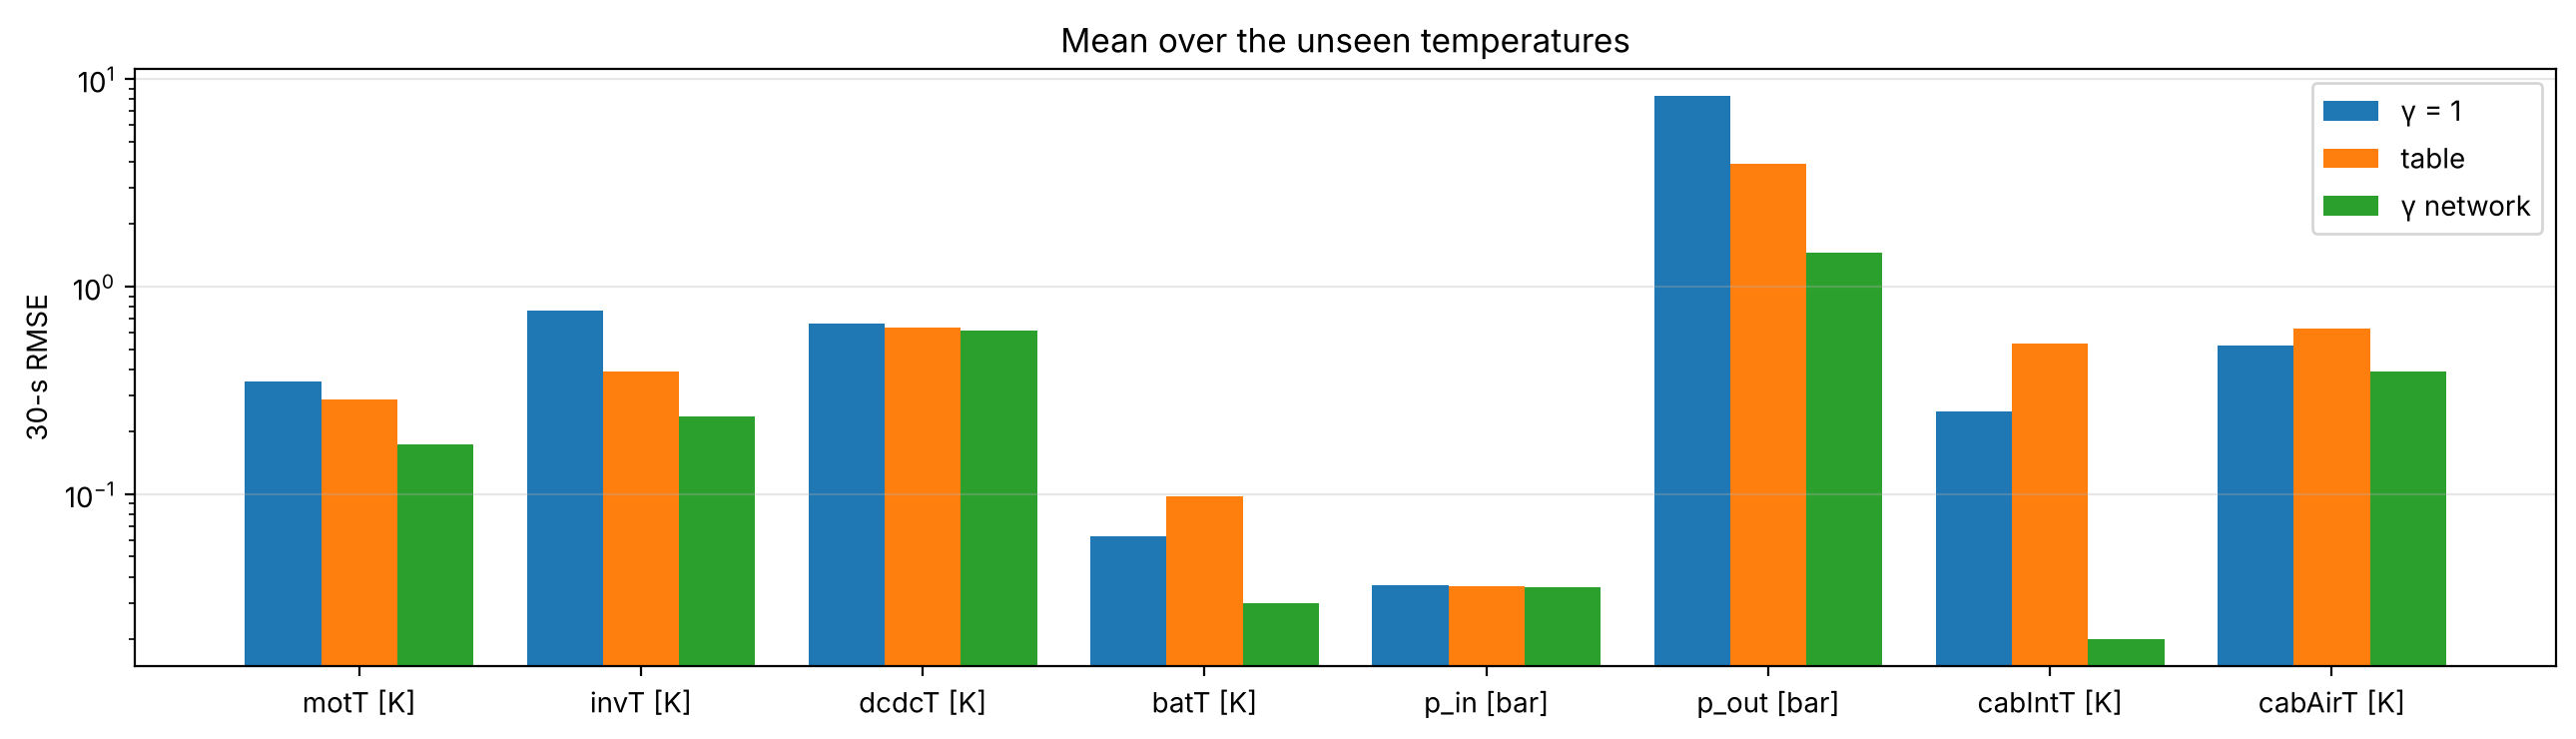

In [4]:
REPORT = [0, 1, 2, 4, 5, 6, 7, 8]
LABELS = ["motT [K]", "invT [K]", "dcdcT [K]", "batT [K]", "p_in [bar]", "p_out [bar]", "cabIntT [K]", "cabAirT [K]"]
results = {}
with torch.no_grad():
    for T in PB:
        w = make_windows(PB[T], H=30, stride=30)
        results[T] = evaluate(w, {"γ = 1": torch.ones(len(w["k0"]), 11, dtype=DT),
                                  "table": table(w["Tamb"].numpy(), w["x0"].numpy()),
                                  "γ network": gamma_net(norm(features(w)))})
names = list(results[TEST_T[0]])
for T in TEST_T + tuple(sorted(set(PB) - set(TEST_T))):
    print(f"\nTamb = {-T:+d} °C ({'UNSEEN' if T in TEST_T else 'train'})    " + "".join(f"{l:>12s}" for l in LABELS))
    for name, r in results[T].items():
        print(f"  {name:12s}          " + "".join(f"{r[i].item():12.3f}" for i in REPORT))

fig, ax = plt.subplots(figsize=(13, 3.8)); wbar = 0.27
for j, name in enumerate(names):
    v = np.mean([[results[T][name][i].item() for i in REPORT] for T in TEST_T], 0)
    ax.bar(np.arange(len(REPORT)) + (j - 1) * wbar, v, wbar, label=name)
ax.set_xticks(range(len(REPORT))); ax.set_xticklabels(LABELS); ax.set_yscale("log"); ax.grid(alpha=.3, axis="y")
ax.set_ylabel("30-s RMSE"); ax.set_title("Mean over the unseen temperatures"); ax.legend(); plt.tight_layout(); plt.show()

## 4. Free run over the full hour (paper Fig. 2 / Table 1)
The COM starts from the HFM state at t = 0 and runs the whole hour **without resets**, driven by the HFM's
inputs. CoolProp properties are recomputed every second from the COM's **own** state (as in the paper's
validation) and γ is recomputed every second. This is a harder test than the NMPC ever needs, because nothing
corrects the drift.

In [5]:
t0 = time.time()
FR = free_run(PB, {"table": lambda x, k, c: table(c["Tamb"].numpy(), x.numpy()),
                   "γ network": network_gamma_fn(gamma_net, norm)}, list(FREE_RUN_T))
print(f"free run: {time.time() - t0:.0f} s")

ST = [("T_mot", 0, 1), ("T_inv", 1, 1), ("T_dcdc", 2, 1), ("T_b", 4, 1), ("T_cair", 8, 1), ("p_in", 5, 1e-5), ("p_out", 6, 1e-5)]
print("\nRMSE / MAE over the full hour (temperatures °C, pressures bar)")
for T_i, T in enumerate(FREE_RUN_T):
    H = PB[T]["x"].numpy()
    print(f"\nTamb = {-T:+d} °C ({'UNSEEN' if T in TEST_T else 'train'})" + "".join(f"{n:>16s}" for n in FR))
    for lab, i, sc in ST:
        cells = []
        for n, P in FR.items():
            e = (P[T_i, :, i].numpy() - H[:, i]) * sc
            cells.append(f"{np.sqrt(np.mean(e**2)):.2f} / {np.mean(np.abs(e)):.2f}")
        print(f"  {lab:8s}" + "".join(f"{c:>16s}" for c in cells))

free run: 143 s

RMSE / MAE over the full hour (temperatures °C, pressures bar)

Tamb = -10 °C (train)           table       γ network
  T_mot        1.29 / 1.03     0.91 / 0.67
  T_inv        1.17 / 0.96     1.06 / 0.89
  T_dcdc       1.43 / 1.24     1.18 / 0.97
  T_b          1.27 / 1.06     0.78 / 0.69
  T_cair       1.10 / 0.66     0.81 / 0.53
  p_in         0.17 / 0.14     0.22 / 0.21
  p_out        2.51 / 2.15     3.07 / 1.46

Tamb = -7 °C (UNSEEN)           table       γ network
  T_mot        1.22 / 1.02     0.82 / 0.65
  T_inv        1.07 / 0.91     1.14 / 0.68
  T_dcdc       1.23 / 1.12     0.97 / 0.77
  T_b          1.45 / 1.25     0.61 / 0.50
  T_cair       1.36 / 1.05     0.77 / 0.45
  p_in         0.21 / 0.19     0.11 / 0.10
  p_out        2.74 / 2.32     3.83 / 1.81

Tamb = -5 °C (train)           table       γ network
  T_mot        3.40 / 2.75     0.81 / 0.66
  T_inv        3.25 / 2.69     1.42 / 0.64
  T_dcdc       3.37 / 2.98     0.86 / 0.69
  T_b          3.78 / 3.1

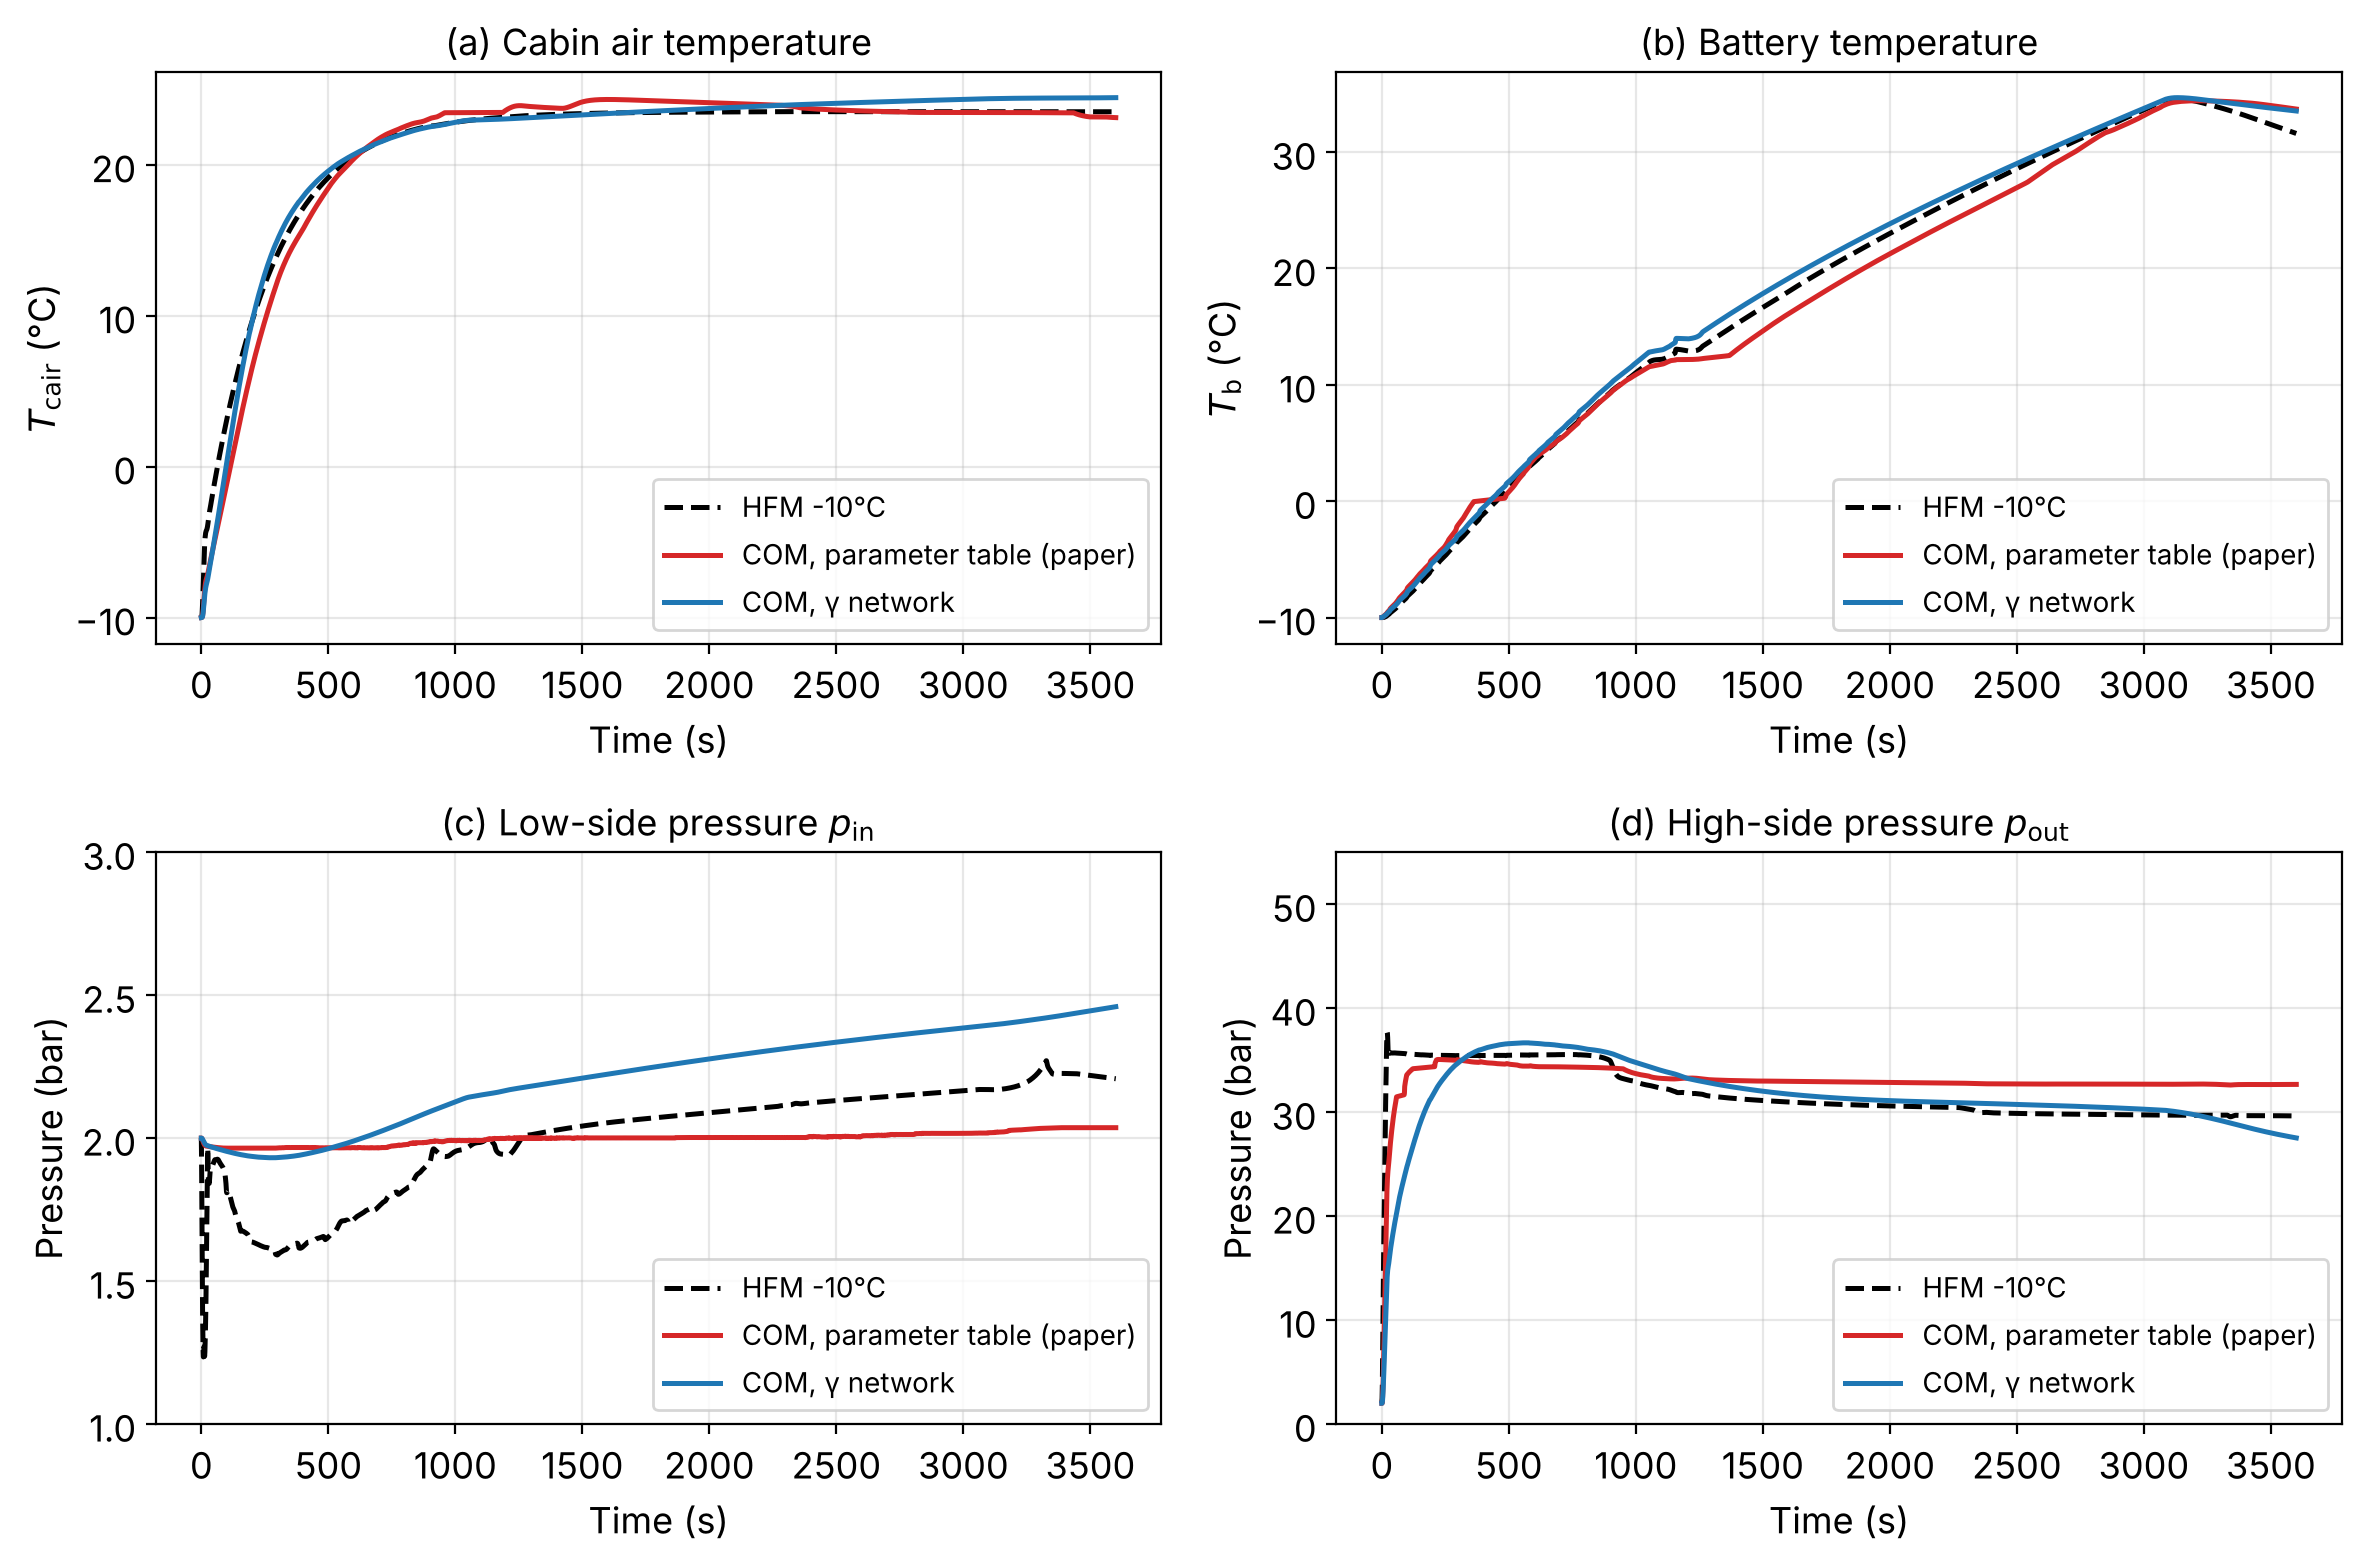

In [6]:
# Fig. 2 style at the first free-run temperature
T = FREE_RUN_T[0]; T_i = 0; H = PB[T]["x"].numpy(); t = np.arange(len(H))
plt.rcParams.update({"font.size": 13}); fig, ax = plt.subplots(2, 2, figsize=(12, 8))
spec = [(8, -273.15, 1, r"$T_\mathrm{cair}$ (°C)", "(a) Cabin air temperature"), (4, -273.15, 1, r"$T_\mathrm{b}$ (°C)", "(b) Battery temperature"),
        (5, 0, 1e-5, "Pressure (bar)", r"(c) Low-side pressure $p_\mathrm{in}$"), (6, 0, 1e-5, "Pressure (bar)", r"(d) High-side pressure $p_\mathrm{out}$")]
style = {"table": ("#d62728", "COM, parameter table (paper)"), "γ network": ("#1f77b4", "COM, γ network")}
for a, (i, off, sc, yl, tl) in zip(ax.flat, spec):
    a.plot(t, (H[:, i] + off) * sc, "k--", lw=1.8, label=f"HFM {-T}°C")
    for n, P in FR.items():
        a.plot(t, (P[T_i, :, i].numpy() + off) * sc, color=style[n][0], lw=1.8, label=style[n][1])
    a.set_xlabel("Time (s)"); a.set_ylabel(yl); a.set_title(tl, fontsize=13); a.grid(alpha=.3); a.legend(fontsize=10, loc="lower right")
ax[1, 0].set_ylim(1, 3); ax[1, 1].set_ylim(0, 55)
plt.tight_layout(); plt.show(); plt.rcParams.update({"font.size": 10})

## 5. What the network does
γ over one unseen cycle compared with the table (30-s windows, log scale).

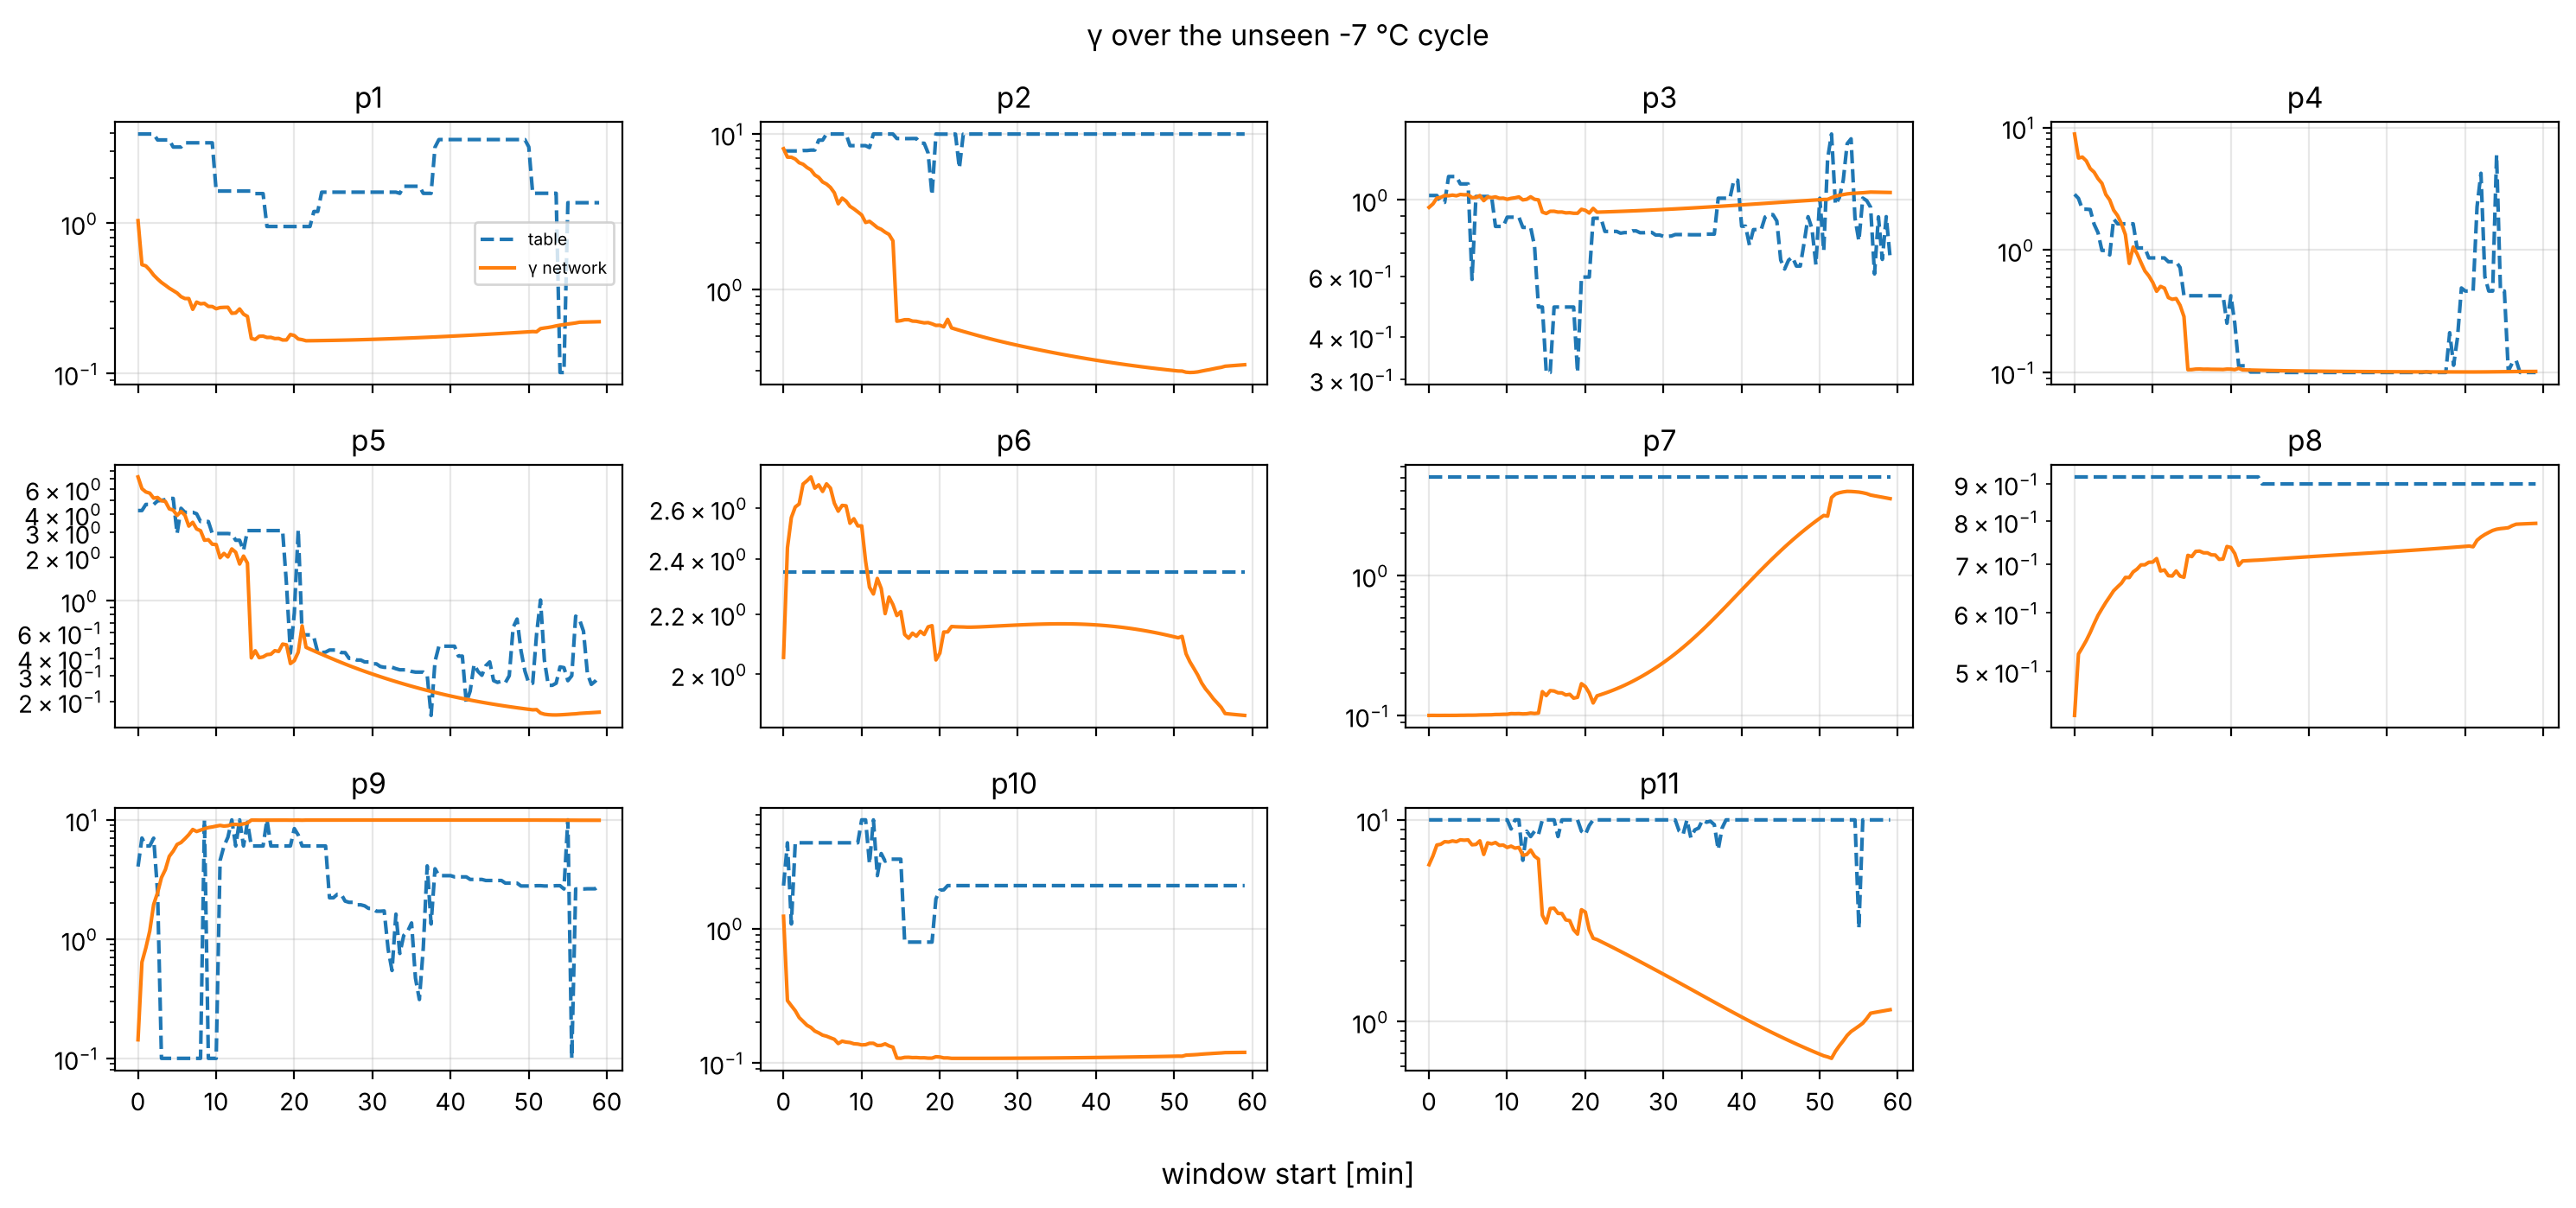

In [7]:
w = make_windows(PB[TEST_T[0]], H=30, stride=30)
with torch.no_grad():
    g_net = gamma_net(norm(features(w))).numpy(); g_tab = table(w["Tamb"].numpy(), w["x0"].numpy()).numpy()
fig, ax = plt.subplots(3, 4, figsize=(15, 7), sharex=True)
for i, a in enumerate(ax.flat[:11]):
    a.plot(w["k0"] / 60, g_tab[:, i], "--", label="table"); a.plot(w["k0"] / 60, g_net[:, i], label="γ network")
    a.set_yscale("log"); a.set_title(f"p{i+1}"); a.grid(alpha=.3)
ax.flat[0].legend(fontsize=7); ax.flat[11].axis("off")
fig.supxlabel("window start [min]"); fig.suptitle(f"γ over the unseen {-TEST_T[0]} °C cycle"); plt.tight_layout(); plt.show()

## 6. More drive cycles: train on three, test on a fourth
Sections 1–5 use one drive cycle (**WLTCHW**: WLTC + 130 km/h highway). Here the network is trained on **several
cycles** and tested on a cycle it has **never seen**.

**Data:** 36 one-hour runs with the rule-based controller = 4 drive cycles × 9 ambient temperatures (0 … −30 °C).
NEDC, UDDS and US06 were made with `RunDriveCycleDataset.m` (18 Nov).

**Split:**
- **Training:** WLTCHW, NEDC and US06 at 0, −5, −10, −15, −20, −30 °C (18 runs).
- **Held out completely:** the whole **UDDS** cycle, and −7, −12, −25 °C on every cycle.

That gives four groups of test difficulty: *train*, *unseen temperature*, *unseen cycle*, *unseen cycle + temperature*.

**Compared** (the COM is the same in all three, only γ changes):

| name | γ comes from |
|---|---|
| **Table (paper)** | the interpolation table tuned at −5/−10 °C on WLTCHW (`prepParaVec`) |
| **Net (WLTCHW)** | the 17 Nov network from sections 2–5, trained on WLTCHW only |
| **Net (3 cycles)** | the new network: same recipe, trained on WLTCHW + NEDC + US06 |

**How it was run:** `python train_gamma11_step1_base.py` (training + every test, capped at 2 h on the desktop PC). It
writes `models/history/gamma11_step1_base.pt` and `results/cycles_experiment_results.pt`; the cells below only load and plot them (a few seconds).

In [2]:
import importlib, report_cycles_experiment as cr
importlib.reload(cr)
from IPython.display import display

RUN_EXPERIMENT = False          # True: train + test again (about 2 h), otherwise load results/cycles_experiment_results.pt
RESULTS_FILE = RESULTS_PY / "cycles_experiment_results.pt"
TABLE_DIR = RESULTS_PY / "tables"; TABLE_DIR.mkdir(exist_ok=True)     # LaTeX versions of the tables for the report

if RUN_EXPERIMENT or not RESULTS_FILE.exists():
    import subprocess, sys
    subprocess.run([sys.executable, "-u", "train_gamma11_step1_base.py"], check=True)
CR = torch.load(RESULTS_FILE, weights_only=False)
PC = load_all_profiles(DATA, RESULTS, CACHE, cycles=("WLTCHW", "NEDC", "UDDS", "US06"), verbose=False)
print(f"{len(CR['horizon'])} runs in the 30-s test, {len(CR['free'])} in the free run; "
      f"training took {CR['train_min']:.0f} min, the whole experiment {CR.get('total_min', float('nan')):.0f} min")

36 runs in the 30-s test, 18 in the free run; training took 60 min, the whole experiment 95 min


### 6.1 The data
The four cycles are quite different: NEDC is a smooth, synthetic cycle; UDDS is stop-and-go city driving;
US06 is aggressive (hard accelerations, up to 129 km/h) and mostly highway.

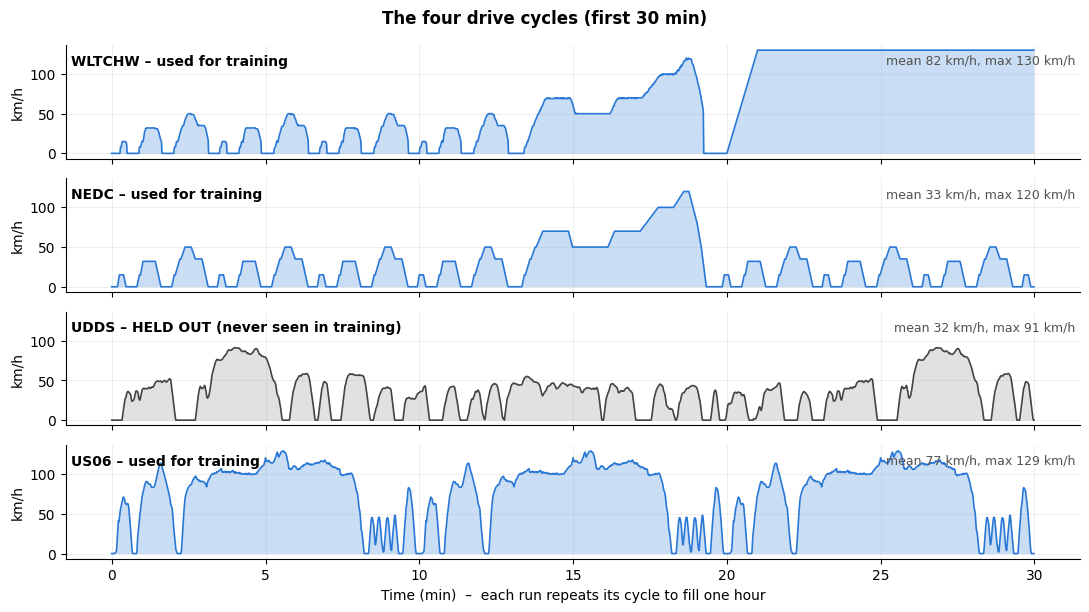

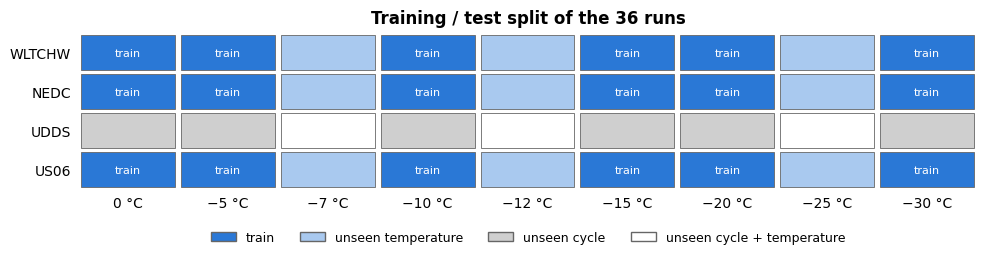

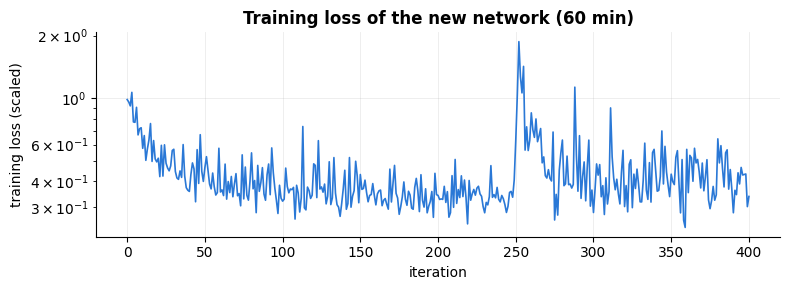

In [3]:
cr.fig_drive_cycles(PC, CR); plt.show()
cr.fig_split(CR); plt.show()
cr.fig_training(CR["hist"], CR["train_min"]); plt.show()

### 6.2 Headline result: error per group of runs
Full-hour **free run** (as in the paper's Fig. 2 / Table 1: start once from the HFM state and predict the whole
hour without resets). Free runs were done at −5/−7/−10 °C on every cycle and at all 9 temperatures on the held-out
UDDS. Each bar is the mean over the runs in that group. **The two right-hand groups are the real test.**

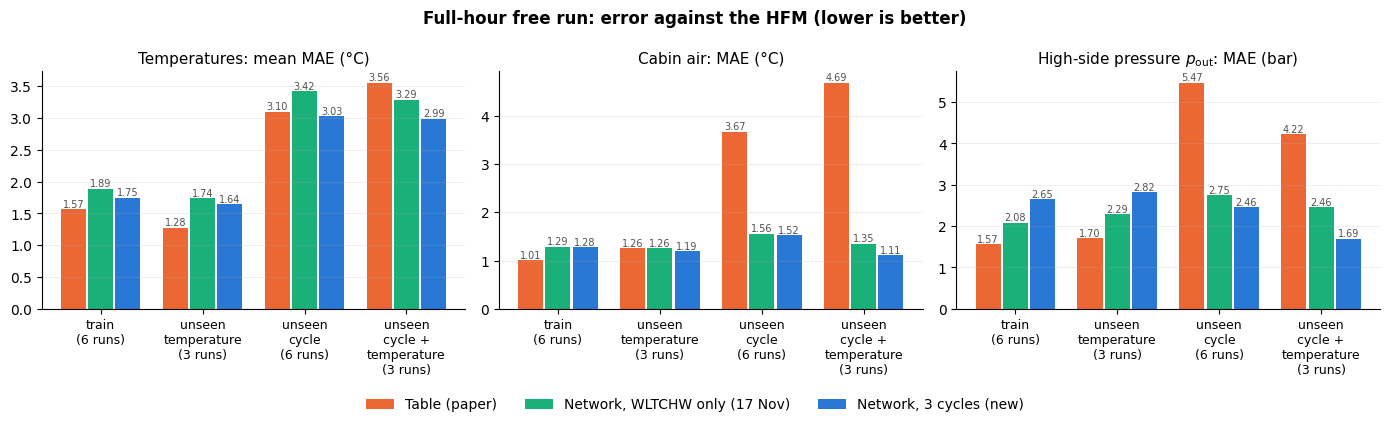

In [4]:
cr.fig_group_bars(CR); plt.show()
df_sum, sty = cr.summary_table(CR); display(sty)

### 6.3 Tables in the style of the paper's Table 1
One table per drive cycle, at the paper's three temperatures (−5, −7, −10 °C). Rows: the paper's five
temperatures plus the two refrigerant pressures; for each, the three ways of getting γ. **Bold = best.**
Remember which runs are unseen: −7 °C on every cycle, and all of UDDS. LaTeX versions are written to `tables/`.

In [5]:
for cyc in ("UDDS", "WLTCHW", "NEDC", "US06"):
    df, sty = cr.table1(CR, cyc)
    note = "HELD-OUT cycle" if cyc == CR["heldout_cycle"] else "training cycle (−7 °C unseen)"
    display(sty.set_caption(f"{cyc} ({note}): free-run RMSE and MAE over the full hour vs the HFM "
                            f"(°C for temperatures, bar for pressures). Bold = best."))
    cr.table1_latex(df, TABLE_DIR / f"table1_{cyc}.tex",
                    caption=f"Free-run RMSE and MAE of the COM against the HFM on {cyc} "
                            f"({'held-out cycle' if cyc == CR['heldout_cycle'] else 'training cycle'}), "
                            "for three sources of $\\gamma$. Temperatures in $^\\circ$C, pressures in bar.",
                    label=f"tab:freerun_{cyc.lower()}")
print("LaTeX tables written to python/tables/table1_<cycle>.tex")

LaTeX tables written to python/tables/table1_<cycle>.tex


### 6.4 The held-out cycle at every temperature
UDDS was never used for training. Lines show the free-run error at each ambient temperature; shaded temperatures
were also never used for training (unseen cycle **and** unseen temperature).

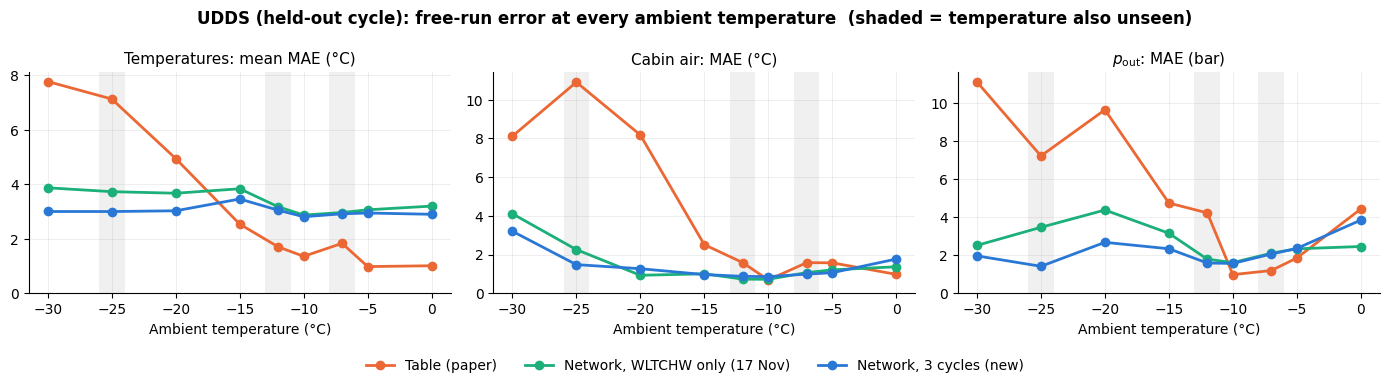

In [6]:
cr.fig_temperature_sweep(CR, CR["heldout_cycle"]); plt.show()

### 6.5 What the trajectories look like (paper Fig. 2 style)
UDDS at −7 °C: both the cycle and the temperature are unseen. Black dashed = HFM (the truth).

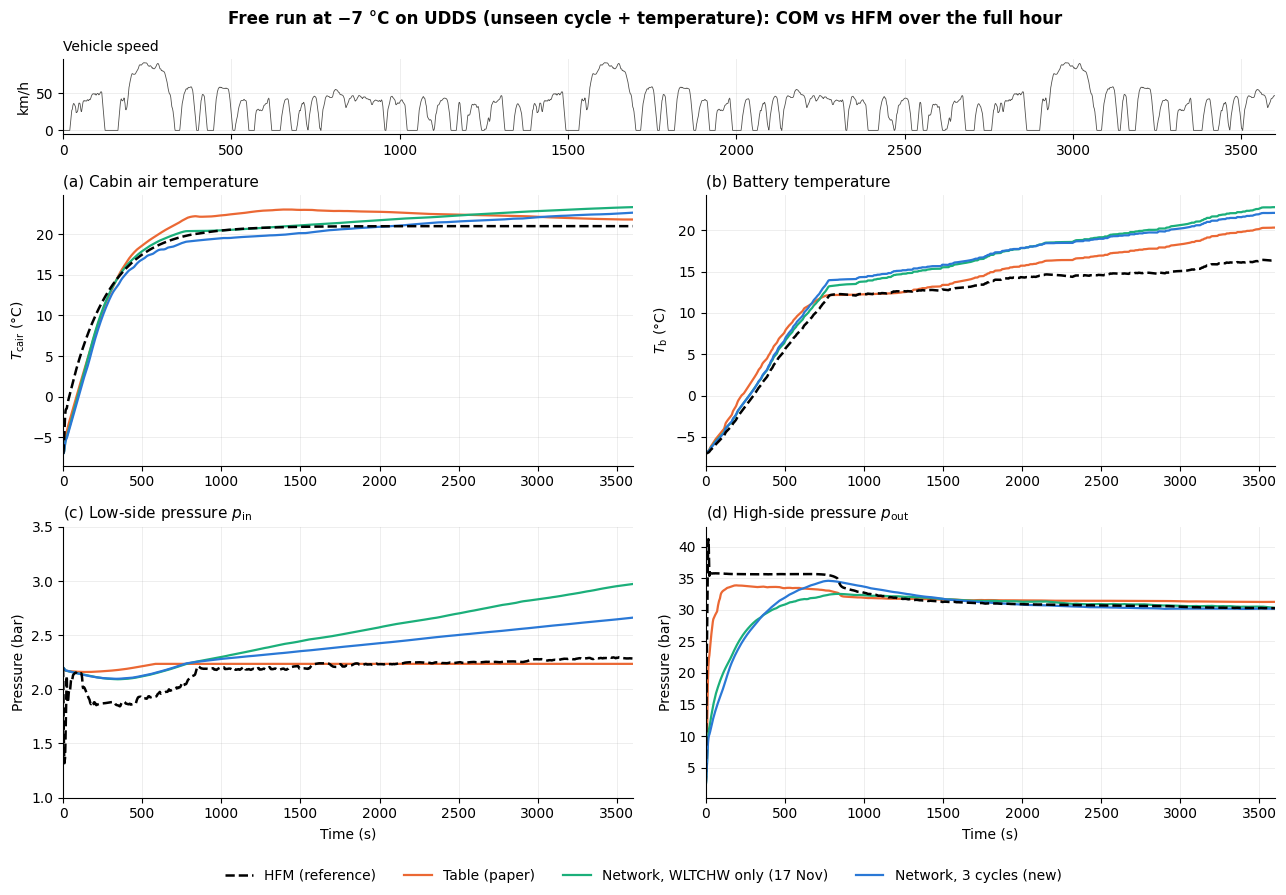

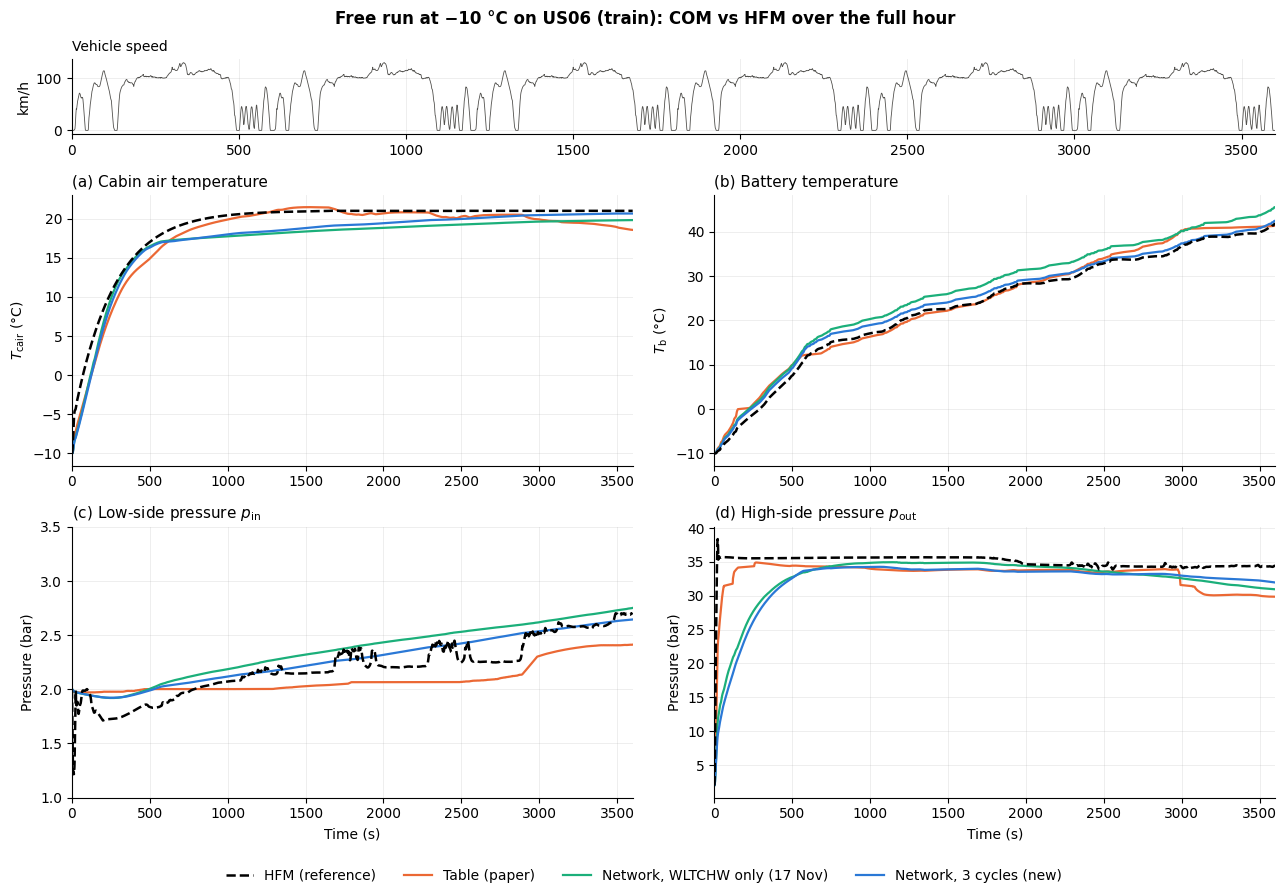

In [7]:
cr.fig_trajectories(CR, PC, cr.key_of(-7, "UDDS")); plt.show()
cr.fig_trajectories(CR, PC, cr.key_of(-10, "US06")); plt.show()

### 6.6 The 30-s test (how the NMPC actually uses the COM)
The NMPC restarts the COM from the measured state every second and only looks 30 s ahead, so this is the error
that matters for control. Mean 30-s RMSE over all 9 temperatures of each cycle (start-up windows included).

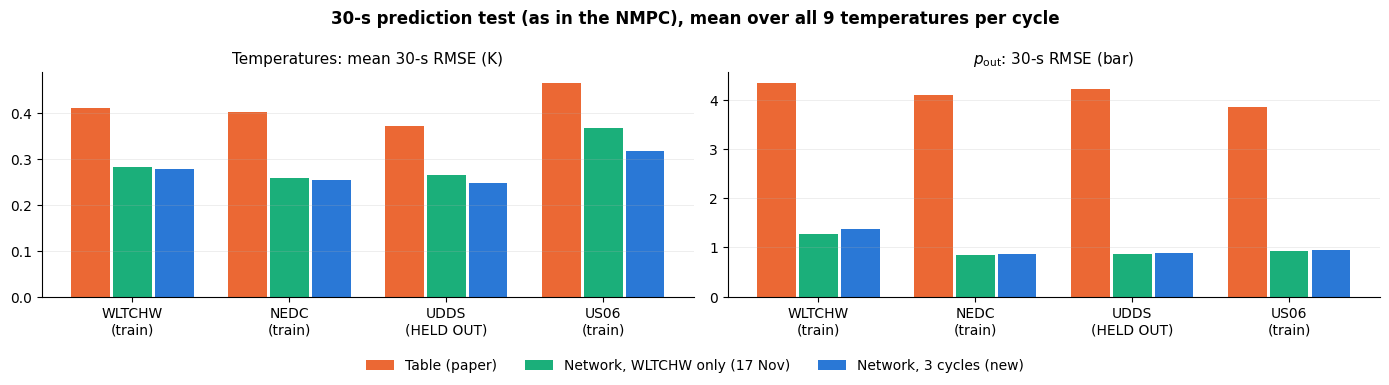

In [8]:
cr.fig_horizon(CR); plt.show()

## What these results show
**Sections 1–5 (one drive cycle, WLTCHW)**
- Test temperatures (−7, −12, −25 °C) were never used for training, but it is the same drive cycle.
- −5 and −10 °C are the table's own tuning temperatures (and probably this exact run): its best case.
- In the free run the network's weakest state is p_in (slow upward drift of ~0.2 bar over the hour).

**Section 6 (four drive cycles; new network trained on WLTCHW + NEDC + US06, UDDS held out)**
1. **The 30-s test, which is how the NMPC uses the COM: both networks beat the table on every cycle,
   including the held-out UDDS.** On UDDS (mean over 9 temperatures): component and cabin temperatures
   0.25 K (new network) / 0.26 K (WLTCHW network) vs 0.37 K (table); p_out 0.9 bar vs 4.2 bar. The network
   trained on WLTCHW alone already transfers to new cycles here, so it has not just memorised its training cycle.
2. **Free run on the held-out cycle: the new network beats the WLTCHW-only network on almost every measure.** It is
   clearly better than the table for the cabin air (UDDS, all 9 temperatures: MAE 1.4 °C vs 4.0 °C) and at the cold temperatures
   (−20 … −30 °C), where the table extrapolates badly.
3. **Free run, motor/inverter/DC-DC/battery on the low-speed cycles (UDDS, NEDC):** the table is better between
   −5 and −15 °C (about 1–2 °C vs about 3.5 °C MAE). All three methods predict these temperatures rising faster
   than the HFM after ~15 min. That points to something the COM misses at low load (e.g. heat rejection in the
   coolant loop), not to γ alone. The networks were trained on 5–20-min windows and drift further in a 60-min free run.
4. **Training on more cycles shares the network's capacity.** The new network is much better on US06 (component
   temperatures about 1 °C vs about 3 °C MAE) but worse than the WLTCHW-only network on WLTCHW itself. The
   WLTCHW-only network `models/history/gamma11_wltchw_only_17nov.pt` stays the model for sections 1–5. The new one is
   `models/history/gamma11_step1_base.pt`.
5. **Free-run p_out:** the table has the lowest MAE at −5 … −10 °C (its tuning range), while the networks rise more
   slowly at start-up. Averaged over all 9 temperatures of the held-out cycle the new network is best (MAE 2.2 bar
   vs 2.7 bar for the WLTCHW-only network and 5.1 bar for the table).

**Limits:** one controller (rule-based); superheat fixed at 2 K (the new exports have no compressor inlet
temperature); step 1 of the new training stopped at 251 of 300 iterations (2-h limit); the interpolation table is
rebuilt with SciPy and can differ slightly from MATLAB. The final check is closed-loop NMPC energy and comfort.
